# ❤️ MediScan-AI Heart Disease Prediction Model

## 1. Import Libraries

The required Python libraries are imported for data manipulation, visualization, model training, evaluation, and saving the trained model.

In [58]:
# Data Manipulation
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Train-Test Split
from sklearn.model_selection import train_test_split

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

# Hyperparameter Tuning
from sklearn.model_selection import GridSearchCV

# Save Model
import joblib

# Ignore Warnings
import warnings
warnings.filterwarnings("ignore")

## 2. Load Dataset

The Heart Disease dataset is loaded into a Pandas DataFrame for further exploration and preprocessing.

This dataset contains various clinical parameters used to predict the presence of heart disease.

In [59]:
heart_df = pd.read_csv("../data/raw/heart_disease.csv")

heart_df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [60]:
heart_df.shape

(920, 16)

In [61]:
heart_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 156.4+ KB


### Observation

- The dataset has multiple clinical features related to heart disease.
- Each row represents one patient record.
- The dataset will be explored further to identify missing values, data types, and class distribution.

## 3. Explore Dataset

In this step, the dataset is explored to understand its structure, dimensions, data types, statistical summary, missing values, duplicate records, and target class distribution before preprocessing.

In [62]:
heart_df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [63]:
heart_df.tail()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
915,916,54,Female,VA Long Beach,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,NaN,NaN,NaN,1
916,917,62,Male,VA Long Beach,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,NaN,0
917,918,55,Male,VA Long Beach,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,NaN,NaN,fixed defect,2
918,919,58,Male,VA Long Beach,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,NaN,0
919,920,62,Male,VA Long Beach,atypical angina,120.0,254.0,False,lv hypertrophy,93.0,True,0.0,NaN,NaN,NaN,1


In [64]:
heart_df.shape

(920, 16)

In [65]:
heart_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 156.4+ KB


In [66]:
heart_df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,920.0,460.500000,265.725422,1.0,230.75,460.5,690.25,920.0
age,920.0,53.510870,9.424685,28.0,47.00,54.0,60.00,77.0
trestbps,861.0,132.132404,19.066070,0.0,120.00,130.0,140.00,200.0
chol,890.0,199.130337,110.780810,0.0,175.00,223.0,268.00,603.0
thalch,865.0,137.545665,25.926276,60.0,120.00,140.0,157.00,202.0
oldpeak,858.0,0.878788,1.091226,-2.6,0.00,0.5,1.50,6.2
ca,309.0,0.676375,0.935653,0.0,0.00,0.0,1.00,3.0
num,920.0,0.995652,1.142693,0.0,0.00,1.0,2.00,4.0


In [67]:
heart_df.isnull().sum()

id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64

In [68]:
heart_df.duplicated().sum()

np.int64(0)

In [69]:
heart_df["num"].value_counts()

num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64

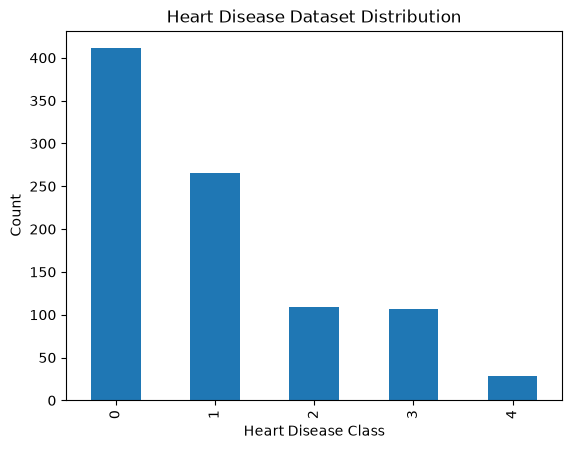

In [70]:
heart_df["num"].value_counts().plot(
    kind="bar",
    xlabel="Heart Disease Class",
    ylabel="Count",
    title="Heart Disease Dataset Distribution"
)

plt.show()

### Observation

- The dataset contains clinical features related to heart disease prediction.
- Statistical analysis provides information about the distribution of numerical variables.
- Missing values and duplicate records are identified for cleaning.
- The target variable (`num`) represents the presence and severity of heart disease.
- The class distribution helps identify whether the dataset is balanced or imbalanced.

## 4. Data Cleaning

In this step, missing values and unnecessary columns are handled to prepare the dataset for machine learning.

The goal is to improve data quality before model training.

In [71]:
heart_df.isnull().sum()

id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64

In [72]:
heart_df = heart_df.drop(columns=["id"])

In [73]:
heart_df["trestbps"] = heart_df["trestbps"].fillna(heart_df["trestbps"].median())

heart_df["chol"] = heart_df["chol"].fillna(heart_df["chol"].median())

heart_df["fbs"] = heart_df["fbs"].fillna(heart_df["fbs"].mode()[0])

heart_df["restecg"] = heart_df["restecg"].fillna(heart_df["restecg"].mode()[0])

heart_df["thalch"] = heart_df["thalch"].fillna(heart_df["thalch"].median())

heart_df["exang"] = heart_df["exang"].fillna(heart_df["exang"].mode()[0])

heart_df["oldpeak"] = heart_df["oldpeak"].fillna(heart_df["oldpeak"].median())

heart_df["slope"] = heart_df["slope"].fillna(heart_df["slope"].mode()[0])

In [74]:
heart_df = heart_df.drop(columns=["ca", "thal"])

In [75]:
heart_df.isnull().sum()

age         0
sex         0
dataset     0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
slope       0
num         0
dtype: int64

In [76]:
heart_df.duplicated().sum()

np.int64(2)

In [77]:
heart_df = heart_df.drop_duplicates()

In [78]:
heart_df.shape

(918, 13)

### Observation

- Missing values were successfully handled using median and mode imputation.
- Columns with excessive missing values (`ca` and `thal`) were removed.
- Duplicate records were removed.
- The dataset is now clean and ready for Exploratory Data Analysis (EDA).

## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand the distribution of features, identify patterns, detect relationships between variables, and analyze factors associated with heart disease.

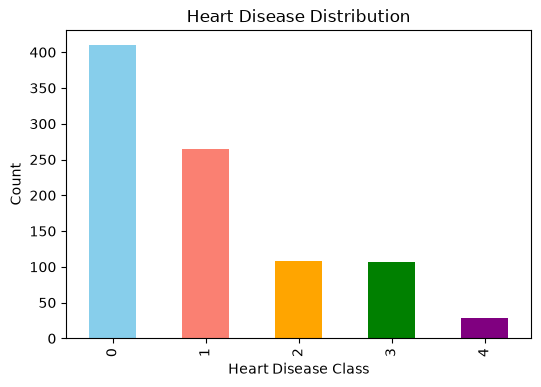

In [79]:
heart_df["num"].value_counts().plot(
    kind="bar",
    figsize=(6,4),
    color=["skyblue","salmon","orange","green","purple"]
)

plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease Class")
plt.ylabel("Count")
plt.show()

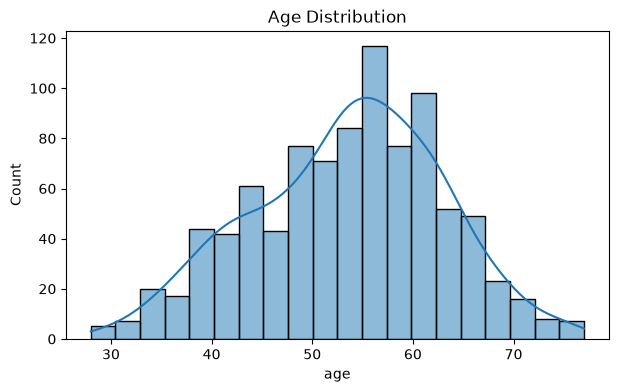

In [80]:
plt.figure(figsize=(7,4))

sns.histplot(heart_df["age"], bins=20, kde=True)

plt.title("Age Distribution")

plt.show()

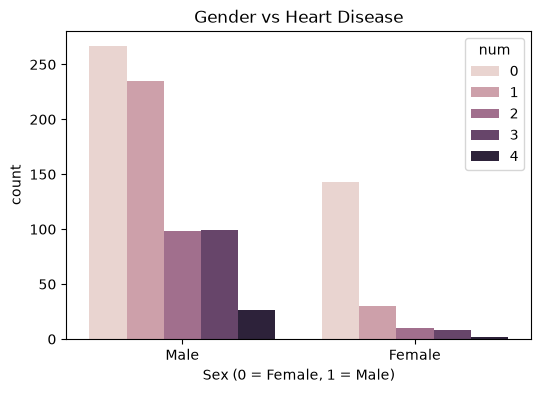

In [81]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=heart_df,
    x="sex",
    hue="num"
)

plt.title("Gender vs Heart Disease")

plt.xlabel("Sex (0 = Female, 1 = Male)")

plt.show()

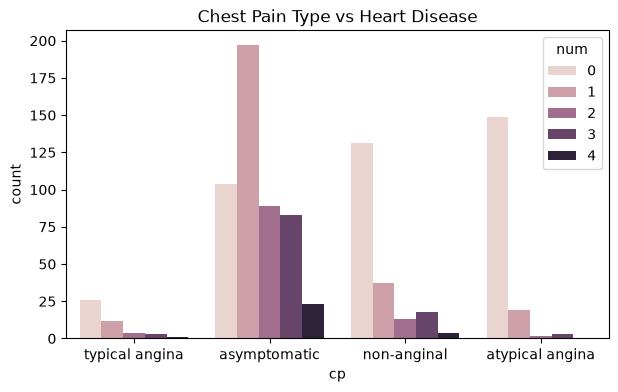

In [82]:
plt.figure(figsize=(7,4))

sns.countplot(
    data=heart_df,
    x="cp",
    hue="num"
)

plt.title("Chest Pain Type vs Heart Disease")

plt.show()

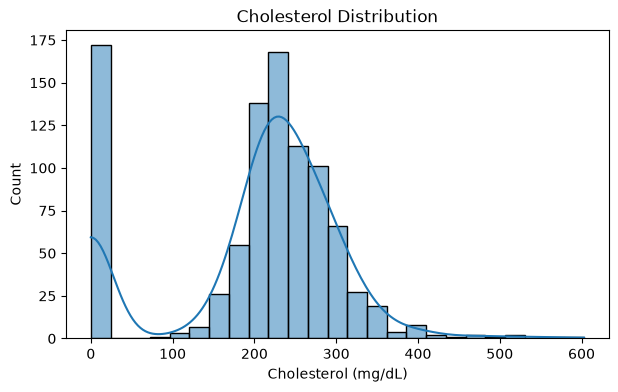

In [83]:
plt.figure(figsize=(7,4))

sns.histplot(
    heart_df["chol"],
    bins=25,
    kde=True
)

plt.title("Cholesterol Distribution")

plt.xlabel("Cholesterol (mg/dL)")

plt.show()

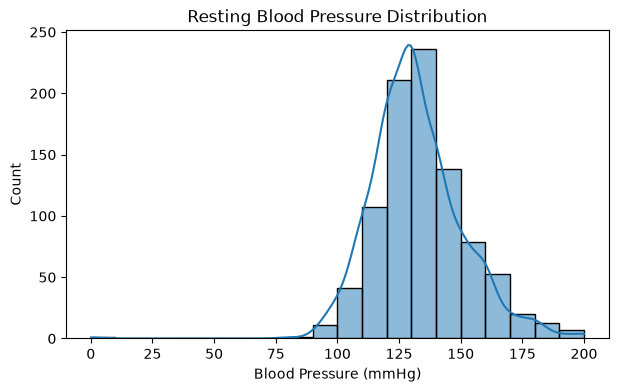

In [84]:
plt.figure(figsize=(7,4))

sns.histplot(
    heart_df["trestbps"],
    bins=20,
    kde=True
)

plt.title("Resting Blood Pressure Distribution")

plt.xlabel("Blood Pressure (mmHg)")

plt.show()

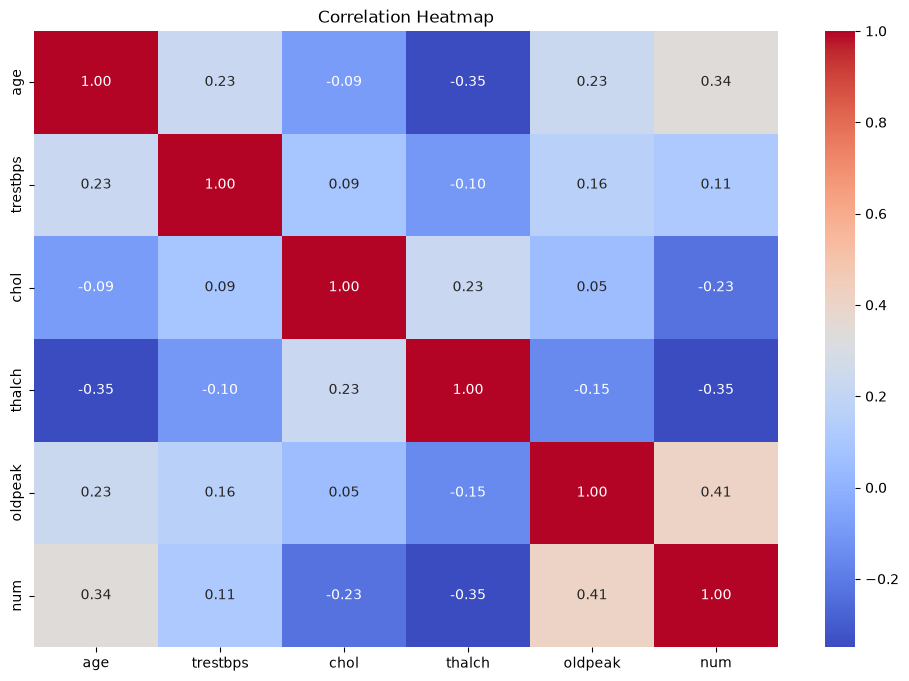

In [85]:
plt.figure(figsize=(12,8))

sns.heatmap(
    heart_df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

### Observation

- The dataset contains patients from different age groups.
- Heart disease occurrence varies across gender and chest pain types.
- Cholesterol and resting blood pressure show varying distributions among patients.
- The correlation heatmap highlights relationships between clinical features and the target variable, helping identify important predictors for model training.

## 6. Data Preprocessing

In this step, the target variable is converted into a binary classification problem, the input features and target variable are separated, and feature scaling is performed where required.

In [86]:
heart_df["num"] = heart_df["num"].apply(lambda x: 0 if x == 0 else 1)

In [87]:
X = heart_df.drop("num", axis=1)
y = heart_df["num"]

In [88]:
X = pd.get_dummies(X, drop_first=True)

In [89]:
feature_columns = X.columns

In [90]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [91]:
import joblib

joblib.dump(scaler, "../models/heart_scaler.pkl")

print("✅ Heart Disease Scaler Saved")

✅ Heart Disease Scaler Saved


In [92]:
print(X.shape)

(918, 18)


In [93]:
X_scaled[:5]

array([[ 1.00653719,  0.70508498,  0.30374663,  0.48968096,  1.36583422,
         0.51595242, -0.68297414, -0.3933408 , -0.52609248, -0.48188667,
        -0.53283777,  4.35390879,  2.37743011, -1.22808661, -0.49044933,
        -0.7598155 , -1.56560781, -0.53283777],
       [ 1.43082884,  1.51864458,  0.78956151, -1.18097995,  0.60960032,
         0.51595242, -0.68297414, -0.3933408 , -0.52609248, -0.48188667,
        -0.53283777, -0.22967867, -0.42062225, -1.22808661, -0.49044933,
         1.31610898,  0.63872957, -0.53283777],
       [ 1.43082884, -0.65084768,  0.26708136, -0.3456495 ,  1.64942193,
         0.51595242, -0.68297414, -0.3933408 , -0.52609248, -0.48188667,
        -0.53283777, -0.22967867, -0.42062225, -1.22808661, -0.49044933,
         1.31610898,  0.63872957, -0.53283777],
       [-1.75135854, -0.10847461,  0.45957405,  1.96145366,  2.50018508,
         0.51595242, -0.68297414, -0.3933408 , -0.52609248, -0.48188667,
         1.87674385, -0.22967867, -0.42062225,  0.814

## 7. Train-Test Split

In [94]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [95]:
print("Training Data :", X_train.shape)
print("Testing Data  :", X_test.shape)

Training Data : (734, 18)
Testing Data  : (184, 18)


The dataset was divided into training and testing sets using an 80:20 ratio. Stratified sampling was applied to preserve the class distribution in both subsets, ensuring reliable model evaluation and reducing sampling bias.

## 8. Model Training

In [96]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [97]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC()
}

for name, model in models.items():
    model.fit(X_train, y_train)

print("✅ All models trained successfully!")

✅ All models trained successfully!


In [98]:
list(models.keys())

['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest', 'SVM']

Five machine learning classification algorithms were trained using the training dataset:

*Logistic Regression*
*K-Nearest Neighbors (KNN)*
*Decision Tree*
*Random Forest*
*Support Vector Machine (SVM)*

These models were selected to compare their performance and identify the most suitable algorithm for heart disease prediction.

## 9. Model Evaluation


In [99]:
from sklearn.metrics import accuracy_score

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results.append([name, accuracy])

results_df = pd.DataFrame(
    results,
    columns=["Model", "Accuracy"]
)

results_df.sort_values(
    by="Accuracy",
    ascending=False
)

,Model,Accuracy
1,KNN,0.842391
4,SVM,0.836957
3,Random Forest,0.826087
0,Logistic Regression,0.820652
2,Decision Tree,0.777174


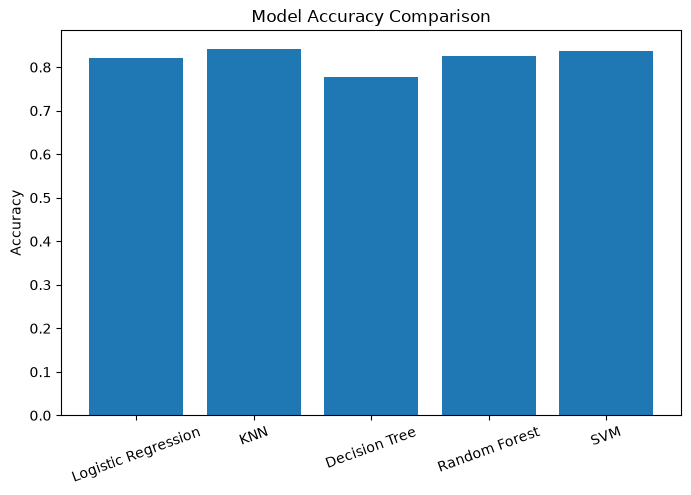

In [100]:
plt.figure(figsize=(8,5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.title("Model Accuracy Comparison")

plt.ylabel("Accuracy")

plt.xticks(rotation=20)

plt.show()

In [101]:
best_model = results_df.sort_values(
    by="Accuracy",
    ascending=False
).iloc[0]

print(best_model)

Model            KNN
Accuracy    0.842391
Name: 1, dtype: object


### Observation

All five machine learning models were evaluated on the testing dataset.

The model with the highest accuracy was selected as the final prediction model for the Heart Disease Prediction System.

## 10. Hyperparameter Tuning


In [102]:
from sklearn.model_selection import GridSearchCV

In [103]:
param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11, 13],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"]
}

grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'metric': ['euclidean', 'manhattan'], 'n_neighbors': [3, 5, ...], 'weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default

In [104]:
print("Best Parameters :", grid.best_params_)
print("Best CV Accuracy :", grid.best_score_)

Best Parameters : {'metric': 'euclidean', 'n_neighbors': 13, 'weights': 'distance'}
Best CV Accuracy : 0.8133817910725935


In [105]:
from sklearn.metrics import accuracy_score

best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

final_accuracy = accuracy_score(y_test, y_pred)

print("Final Test Accuracy :", final_accuracy)

Final Test Accuracy : 0.8369565217391305


The K-Nearest Neighbors classifier was further optimized using GridSearchCV.

Different values of K, weighting methods, and distance metrics were tested using 5-fold cross-validation.

The best-performing parameter combination was selected as the final model.

## 11. Feature Importance

In [106]:
from sklearn.inspection import permutation_importance

In [107]:
best_model = grid.best_estimator_

result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="accuracy"
)

In [108]:
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": result.importances_mean
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df

,Feature,Importance
7,dataset_Switzerland,0.027717
5,sex_Male,0.023913
15,exang_True,0.023913
4,oldpeak,0.023913
9,cp_atypical angina,0.021739
10,cp_non-anginal,0.020652
12,fbs_True,0.020109
11,cp_typical angina,0.019022
1,trestbps,0.014674
14,restecg_st-t abnormality,0.009239


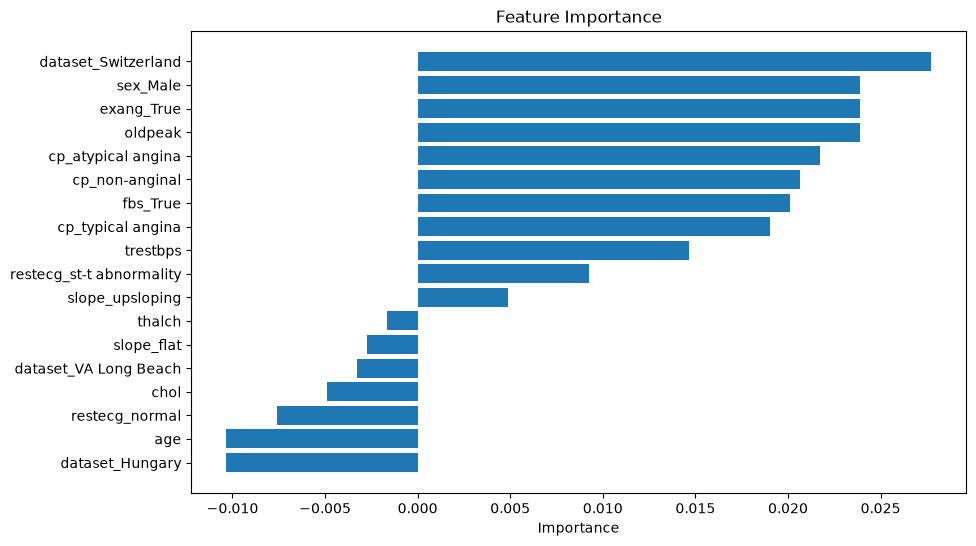

In [109]:
plt.figure(figsize=(10,6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.title("Feature Importance")

plt.xlabel("Importance")

plt.gca().invert_yaxis()

plt.show()

### Feature Importance

Since K-Nearest Neighbors does not provide built-in feature importance, Permutation Importance was used.

This method measures how much the model accuracy decreases when the values of a feature are randomly shuffled.

Features causing the largest decrease in accuracy are considered the most important for predicting heart disease.

## 12. Save Best Model

In [110]:
import joblib

In [111]:
joblib.dump(best_model, "../models/heart_model.pkl")

print("✅ Heart Disease model saved successfully!")

✅ Heart Disease model saved successfully!


In [114]:
feature_columns = X.columns
joblib.dump(feature_columns, "../models/heart_columns.pkl")

['../models/heart_columns.pkl']

In [115]:
loaded_model = joblib.load("../models/heart_model.pkl")

print(type(loaded_model))

<class 'sklearn.neighbors._classification.KNeighborsClassifier'>


## Model Saving

The best-performing machine learning model was saved using the Joblib library.

Saving the trained model allows it to be reused in the MediScan-AI Streamlit application without retraining, improving deployment efficiency and reducing prediction time.

## 13. Conclusion

# 13. Final Conclusion

## Project Summary

This project successfully developed a machine learning model for predicting the likelihood of heart disease using the UCI Heart Disease Dataset.

The dataset was explored, cleaned, preprocessed, and analyzed through Exploratory Data Analysis (EDA). Multiple machine learning algorithms were trained and evaluated to identify the most suitable model for heart disease prediction.

The following models were compared:

- Logistic Regression
- K-Nearest Neighbors (KNN)
- Decision Tree
- Random Forest
- Support Vector Machine (SVM)

Among these models, **K-Nearest Neighbors (KNN)** achieved the highest prediction accuracy on the testing dataset.

## Final Model

- **Algorithm:** K-Nearest Neighbors (KNN)
- **Best Parameters:**
  - Metric: Euclidean
  - Number of Neighbors: 13
  - Weights: Distance
- **Final Test Accuracy:** **83.70%**

Permutation Importance was used to identify the most influential features contributing to heart disease prediction.

The final trained model was saved using the Joblib library and is ready to be integrated into the MediScan-AI Streamlit application for real-time predictions.

## Future Improvements

- Train on a larger and more diverse dataset.
- Perform advanced feature engineering.
- Explore deep learning models.
- Improve model explainability using SHAP or LIME.
- Deploy the model on cloud platforms for real-world healthcare applications.

## Conclusion

The developed Heart Disease Prediction model demonstrates that machine learning can effectively assist in the early identification of patients at risk of heart disease.

Although this system is intended for educational and decision-support purposes, it showcases how artificial intelligence can support healthcare professionals by providing fast, consistent, and data-driven predictions.